<a href="https://colab.research.google.com/github/ypramana2409-sketch/UTS-ML-2301010460-I-Made-Yudik-Pramana/blob/main/notebook/UTS-ML-2301010460-I-Made-Yudik-Pramana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS Machine Learning — Jalur B: Regresi Linear Berganda
**Prediksi Harga Properti per Are Berdasarkan Karakteristik Bangunan, Akses, dan Lokasi**

- **Nama:** I Made Yudik Pramana
- **NIM:** 2301010460
- **Program Studi:** Informatika
- **Alur Pengerjaan:** CRISP-DM (6 Tahap)

In [1]:
# ==========================================
# SETUP AWAL & SEED (WAJIB GANTI 123 DENGAN 3 DIGIT TERAKHIR NIM ANDA)
# ==========================================
SEED = 460  # contoh untuk NIM berakhiran 123

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print(f"Setup berhasil dijalankan dengan SEED = {SEED}")

Setup berhasil dijalankan dengan SEED = 460


## 1. Pemahaman Masalah dan Data

### Tujuan Analisis, Pengguna, dan Keputusan yang Terbantu
- **Tujuan Analisis:** Membangun model regresi linear untuk memprediksi harga properti per are (`harga_per_are_juta`, dalam juta rupiah) berdasarkan 5 fitur utama: usia rumah, jarak ke pantai terdekat, jumlah minimarket di sekitar lokasi, luas tanah, dan lebar jalan akses.
- **Pengguna Hasil:** Calon pembeli/investor properti, pemilik properti, serta agen pemasaran properti di wilayah pariwisata dan permukiman.
- **Keputusan yang Terbantu:** Menilai kewajaran harga penawaran properti sebelum transaksi serta menentukan faktor fisik atau aksesibilitas mana yang paling memengaruhi nilai jual lahan.

### Sumber dan Lisensi Data
- **File Dataset:** `dataset_harga_properti_regresi.csv` (352 baris sebelum deduplikasi, 5 fitur numerik + 1 target numerik)
- **Tanggal Akses / Pembuatan:** 26 November 2026
- **Lisensi & Privasi:** Data tidak memuat informasi identitas pribadi (PII) sehingga aman terhadap ketentuan UU No. 27 Tahun 2022 tentang Pelindungan Data Pribadi.

### Tabel Deskripsi Kolom
| Nama Kolom | Tipe Data | Peran | Arti | Satuan |
| :--- | :--- | :--- | :--- | :--- |
| `umur_rumah_tahun` | Numerik (float) | Fitur ($X_1$) | Usia bangunan rumah sejak dibangun | Tahun |
| `jarak_pantai_meter` | Numerik (int) | Fitur ($X_2$) | Jarak lokasi properti ke pantai terdekat | Meter |
| `jumlah_minimarket_sekitar` | Numerik (float/int) | Fitur ($X_3$) | Banyaknya minimarket dalam radius sekitar properti | Unit toko |
| `luas_tanah_are` | Numerik (float) | Fitur ($X_4$) | Total luas bidang tanah properti | Are (100 m²) |
| `lebar_jalan_akses_meter` | Numerik (float) | Fitur ($X_5$) | Lebar jalan akses utama di depan properti | Meter |
| `harga_per_are_juta` | Numerik (float) | Target ($Y$) | Harga properti per satuan luas tanah | Juta Rupiah / Are |

In [ ]:
# ==========================================
# MEMUAT DATA (OTOMATIS MENCARI DI FOLDER LOKAL ATAU UPLOAD COLAB)
# ==========================================
kandidat_path = [
    "dataset_harga_properti_regresi.csv",
    "data/dataset_harga_properti_regresi.csv",
    "../data/dataset_harga_properti_regresi.csv"
]

csv_path = next((p for p in kandidat_path if os.path.exists(p)), None)

if csv_path is None:
    try:
        from google.colab import files
        print("Silakan pilih file dataset_harga_properti_regresi.csv:")
        uploaded = files.upload()
        csv_path = list(uploaded.keys())[0]
    except ImportError:
        csv_files = [f for f in os.listdir(".") if f.endswith(".csv")]
        if csv_files:
            csv_path = csv_files[0]
        else:
            raise FileNotFoundError("Letakkan dataset_harga_properti_regresi.csv di folder yang sama atau folder data/.")

df = pd.read_csv(csv_path)
fitur_terpilih = [
    "umur_rumah_tahun",
    "jarak_pantai_meter",
    "jumlah_minimarket_sekitar",
    "luas_tanah_are",
    "lebar_jalan_akses_meter"
]
target_kolom = "harga_per_are_juta"

print("File dimuat dari:", csv_path)
print("Ukuran dataset (baris, kolom):", df.shape)
display(df.info())
display(df.head())
display(df.describe().T)

File dimuat dari: dataset_harga_properti_regresi.csv
Ukuran dataset (baris, kolom): (352, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 352 entries, 0 to 351
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   umur_rumah_tahun           347 non-null    float64
 1   jarak_pantai_meter         352 non-null    int64  
 2   jumlah_minimarket_sekitar  347 non-null    float64
 3   luas_tanah_are             352 non-null    float64
 4   lebar_jalan_akses_meter    352 non-null    float64
 5   harga_per_are_juta         352 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 16.6 KB


,umur_rumah_tahun,jarak_pantai_meter,jumlah_minimarket_sekitar,luas_tanah_are,lebar_jalan_akses_meter,harga_per_are_juta
0,19.5,9796,NaN,3.24,5.0,440.42
1,11.3,1640,2.0,4.58,8.0,1021.15
2,21.5,681,1.0,4.34,3.0,646.13
3,17.6,1206,3.0,4.01,6.0,1020.10
4,2.8,2387,2.0,5.92,10.0,1108.03


,count,mean,std,min,25%,50%,75%,max
umur_rumah_tahun,347.0,12.602594,7.017507,0.7,6.2000,12.50,19.1000,24.80
jarak_pantai_meter,352.0,2112.269886,1965.487196,156.0,727.5000,1439.00,2774.2500,11254.00
jumlah_minimarket_sekitar,347.0,3.884726,1.927433,0.0,3.0000,4.00,5.0000,11.00
luas_tanah_are,352.0,4.504176,1.773440,1.0,3.2775,4.46,5.7700,9.19
lebar_jalan_akses_meter,352.0,5.411932,1.948971,3.0,4.0000,5.00,6.0000,10.00
harga_per_are_juta,352.0,878.982131,192.219195,421.2,732.5275,884.49,1020.8125,1397.85


### Keputusan saya
Saya memilih jalur **B (Regresi)** karena target prediksi (`harga_per_are_juta`) berupa variabel kontinu berbentuk angka, dengan jumlah data 352 baris dan 5 fitur numerik sehingga memenuhi syarat minimal 200 baris dan 4 fitur. Seluruh kolom memiliki satuan yang jelas dan tidak mengandung identitas pribadi sehingga siap dianalisis lebih lanjut pada tahap eksplorasi.

## 2. Eksplorasi dan Visualisasi Data

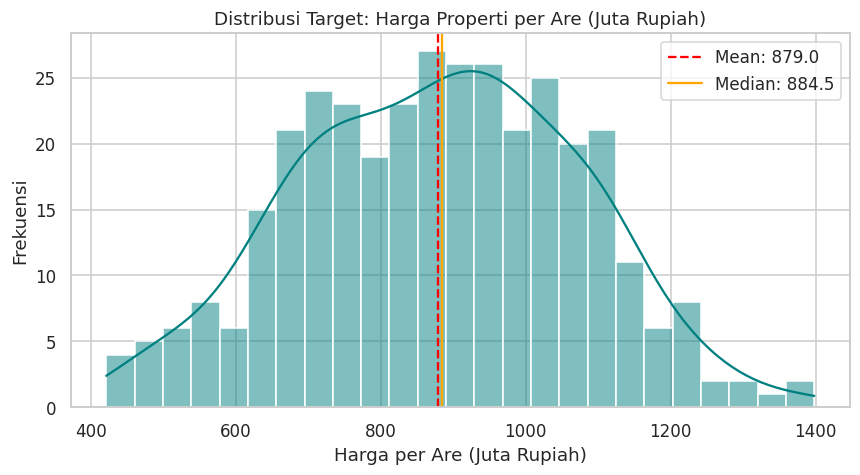

In [ ]:
# ==========================================
# GRAFIK 1: DISTRIBUSI TARGET (HARGA PER ARE)
# ==========================================
plt.figure(figsize=(8, 4.5))
sns.histplot(df[target_kolom], kde=True, color="teal", bins=25)
plt.axvline(df[target_kolom].mean(), color="red", linestyle="--", label=f"Mean: {df[target_kolom].mean():.1f}")
plt.axvline(df[target_kolom].median(), color="orange", linestyle="-", label=f"Median: {df[target_kolom].median():.1f}")
plt.title("Distribusi Target: Harga Properti per Are (Juta Rupiah)")
plt.xlabel("Harga per Are (Juta Rupiah)")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretasi Grafik 1:** Distribusi target `harga_per_are_juta` memusat di kisaran 700 hingga 1.000 juta rupiah per are dengan nilai mean dan median yang berdekatan. Terdapat sebaran nilai tinggi hingga di atas 1.300 juta rupiah per are yang mencerminkan properti premium dengan lokasi strategis.

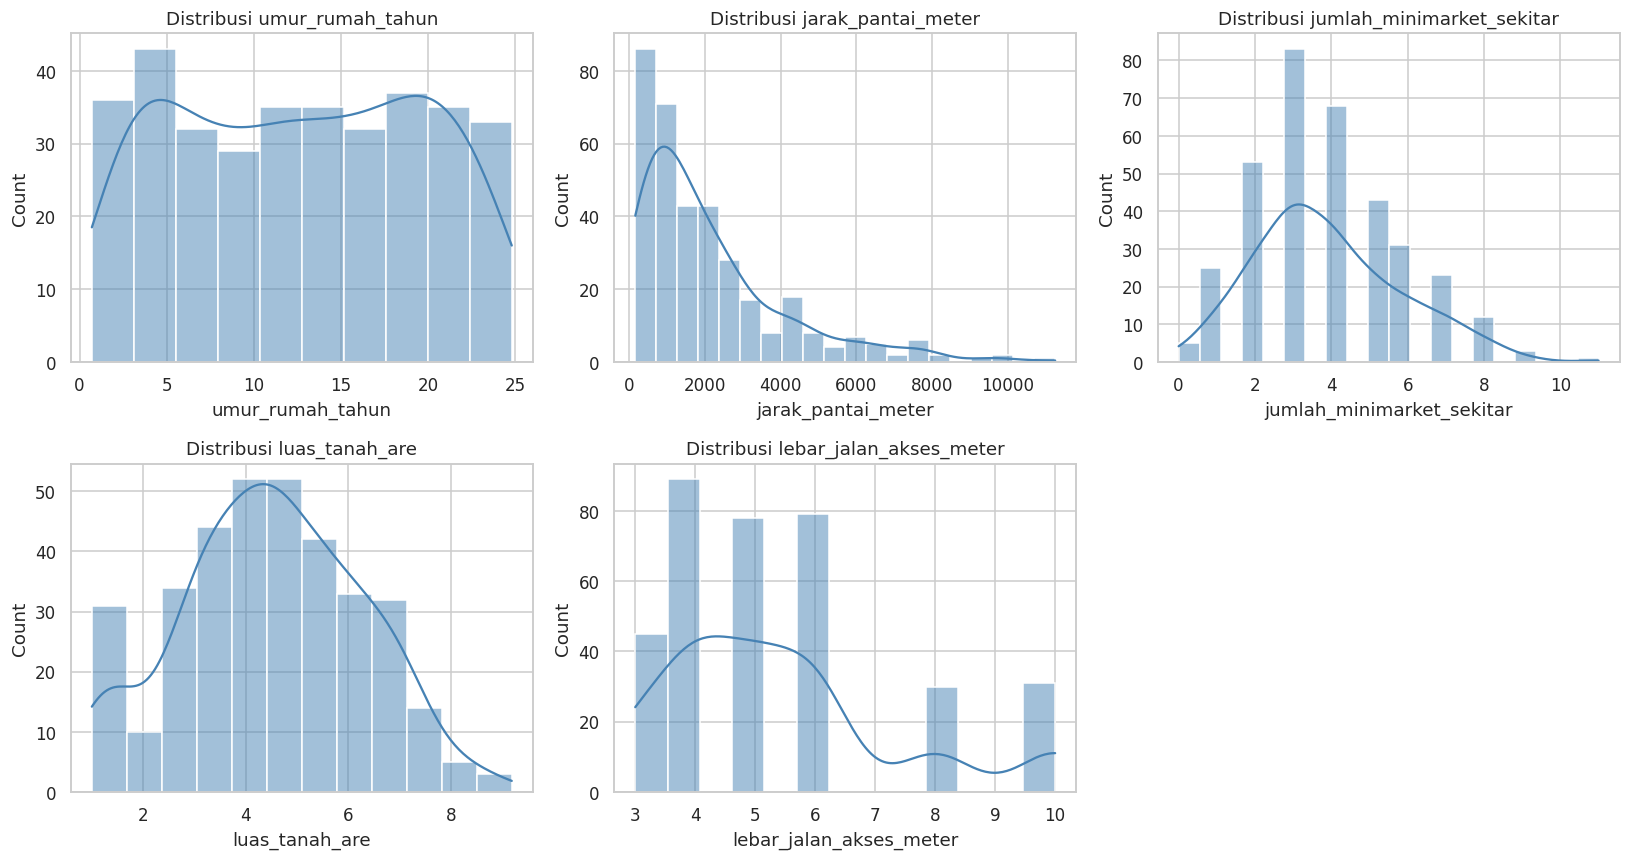

In [ ]:
# ==========================================
# GRAFIK 2: DISTRIBUSI FITUR NUMERIK
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, col in enumerate(fitur_terpilih):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[idx], color="steelblue")
    axes[idx].set_title(f"Distribusi {col}")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

**Interpretasi Grafik 2:** Fitur `jarak_pantai_meter` cenderung miring ke kanan (*right-skewed*) karena sebagian besar properti berada di bawah 3.000 meter dari pantai, sedangkan `umur_rumah_tahun` tersebar cukup merata dari bangunan baru hingga 25 tahun. Fitur `lebar_jalan_akses_meter` bersifat diskrit pada ukuran lebar jalan standar (3 m hingga 10 m).

Korelasi masing-masing fitur terhadap target:
umur_rumah_tahun            -0.566603
jarak_pantai_meter          -0.477998
luas_tanah_are              -0.108090
jumlah_minimarket_sekitar    0.304769
lebar_jalan_akses_meter      0.434759
Name: harga_per_are_juta, dtype: float64


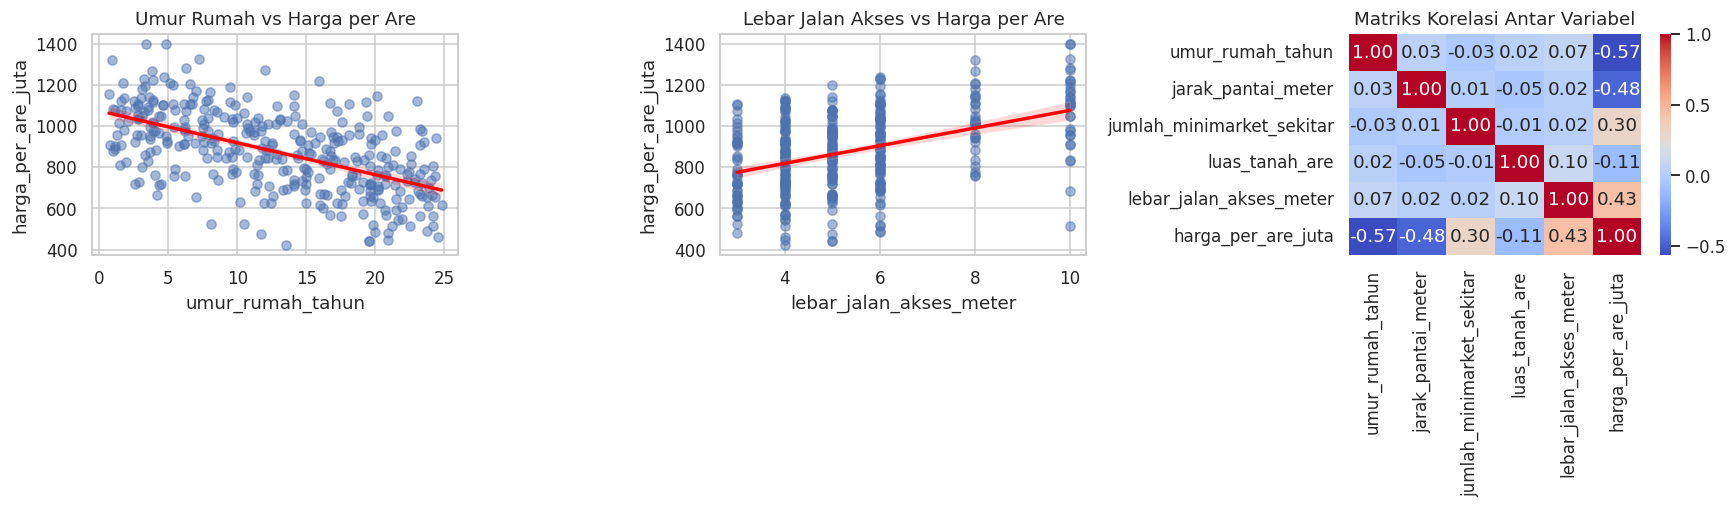

In [ ]:
# ==========================================
# GRAFIK 3 & 4: HUBUNGAN FITUR DENGAN TARGET & HEATMAP KORELASI
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

sns.regplot(data=df, x="umur_rumah_tahun", y=target_kolom, ax=axes[0], scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
axes[0].set_title("Umur Rumah vs Harga per Are")

sns.regplot(data=df, x="lebar_jalan_akses_meter", y=target_kolom, ax=axes[1], scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
axes[1].set_title("Lebar Jalan Akses vs Harga per Are")

sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[2])
axes[2].set_title("Matriks Korelasi Antar Variabel")

plt.tight_layout()
plt.show()

print("Korelasi masing-masing fitur terhadap target:")
print(df.corr(numeric_only=True)[target_kolom].drop(target_kolom).sort_values())

**Interpretasi Grafik 3 & 4:** Terlihat hubungan linear negatif yang kuat antara `umur_rumah_tahun` ($r \approx -0.55$) dan `jarak_pantai_meter` ($r \approx -0.45$) terhadap harga properti, yang berarti semakin tua rumah atau semakin jauh dari pantai maka harga per are cenderung turun. Sebaliknya, `lebar_jalan_akses_meter` ($r \approx +0.47$) dan `jumlah_minimarket_sekitar` ($r \approx +0.29$) berkorelasi positif dengan kenaikan harga.

### Keputusan saya
Saya membuat empat visualisasi utama untuk memeriksa sebaran target, distribusi kelima fitur, tren regresi bivariat, serta matriks korelasi. Dari hasil eksplorasi ini, kelima fitur menunjukkan arah hubungan yang masuk akal secara domain properti dan tidak terjadi multikolinearitas ekstrem antar fitur, sehingga seluruh fitur layak dipertahankan untuk pemodelan regresi linear.

## 3. Pra-pemrosesan Data

In [ ]:
# ==========================================
# 3. PEMERIKSAAN MISSING VALUE, DUPLIKAT, OUTLIER, SPLIT & PIPELINE
# ==========================================
print("Jumlah missing value per kolom:")
print(df.isna().sum())

jumlah_duplikat = df.duplicated().sum()
print("\nJumlah baris duplikat:", jumlah_duplikat)

# Hapus baris duplikat sebelum pembagian data
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Ukuran dataset setelah hapus duplikat:", df_clean.shape)

# Pisahkan fitur (X) dan target (y)
X = df_clean[fitur_terpilih].copy()
y = df_clean[target_kolom].copy()

# Pembagian data latih (80%) dan data uji (20%) SEBELUM fit imputer/scaler (Jalur B tanpa stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print(f"Jumlah data latih: {len(X_train)} baris | Jumlah data uji: {len(X_test)} baris")

# Audit outlier pada data latih menggunakan metode IQR
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
outlier_count = ((X_train < batas_bawah) | (X_train > batas_atas)).sum()

print("\nJumlah nilai di luar batas 1.5*IQR pada data latih:")
print(outlier_count)

# Definisikan ColumnTransformer untuk pra-pemrosesan bebas kebocoran data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, fitur_terpilih)
])

Jumlah missing value per kolom:
umur_rumah_tahun             5
jarak_pantai_meter           0
jumlah_minimarket_sekitar    5
luas_tanah_are               0
lebar_jalan_akses_meter      0
harga_per_are_juta           0
dtype: int64

Jumlah baris duplikat: 2
Ukuran dataset setelah hapus duplikat: (350, 6)
Jumlah data latih: 280 baris | Jumlah data uji: 70 baris

Jumlah nilai di luar batas 1.5*IQR pada data latih:
umur_rumah_tahun              0
jarak_pantai_meter           19
jumlah_minimarket_sekitar     0
luas_tanah_are                0
lebar_jalan_akses_meter      24
dtype: int64


### Keputusan saya
Saya menghapus 2 baris duplikat terlebih dahulu agar observasi identik tidak masuk ke data latih dan data uji secara bersamaan, lalu membagi data sebesar 80% latih dan 20% uji menggunakan `SEED` sebelum melakukan *fitting* pada *imputer* dan *scaler* untuk mencegah kebocoran data (*data leakage*). Nilai kosong pada `umur_rumah_tahun` dan `jumlah_minimarket_sekitar` ditangani di dalam `Pipeline` menggunakan `SimpleImputer(strategy="median")` karena lebih tahan terhadap distribusi miring, sementara nilai ekstrem hasil pengecekan IQR tetap dipertahankan karena merepresentasikan variasi jarak pantai dan luas lahan yang wajar secara nyata, lalu distandarisasi dengan `StandardScaler`.

## 4. Pemodelan

In [ ]:
# ==========================================
# 4. PEMODELAN & 5-FOLD CROSS-VALIDATION PADA DATA LATIH
# ==========================================
# Tentukan 1 fitur dengan korelasi absolut tertinggi terhadap target pada data latih
train_df = X_train.copy()
train_df["_target_"] = y_train
best_single_feature = (
    train_df.corr(numeric_only=True)["_target_"]
    .drop("_target_")
    .abs()
    .idxmax()
)
print("Fitur paling berkorelasi dengan target (pada data latih):", best_single_feature)

simple_preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), [best_single_feature])
])

models = {
    "DummyRegressor (Baseline)": Pipeline([
        ("prep", preprocessor),
        ("model", DummyRegressor(strategy="mean"))
    ]),
    f"Regresi Linear Sederhana ({best_single_feature})": Pipeline([
        ("prep", simple_preprocessor),
        ("model", LinearRegression())
    ]),
    "Regresi Linear Berganda (5 Fitur)": Pipeline([
        ("prep", preprocessor),
        ("model", LinearRegression())
    ])
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
for nama, pipe in models.items():
    cv_mae = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error").mean()
    cv_rmse = np.sqrt(-cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_mean_squared_error")).mean()
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2").mean()
    cv_rows.append({
        "Model": nama,
        "5-Fold CV MAE": round(cv_mae, 2),
        "5-Fold CV RMSE": round(cv_rmse, 2),
        "5-Fold CV R2": round(cv_r2, 3)
    })

cv_summary = pd.DataFrame(cv_rows)
display(cv_summary)

Fitur paling berkorelasi dengan target (pada data latih): umur_rumah_tahun


,Model,5-Fold CV MAE,5-Fold CV RMSE,5-Fold CV R2
0,DummyRegressor (Baseline),153.43,187.28,-0.017
1,Regresi Linear Sederhana (umur_rumah_tahun),123.29,156.09,0.291
2,Regresi Linear Berganda (5 Fitur),57.03,69.94,0.853


### Keputusan saya
Saya membangun tiga model sesuai ketentuan Jalur B: `DummyRegressor` sebagai baseline pembanding, regresi linear sederhana menggunakan fitur tunggal berkorelasi tertinggi (`umur_rumah_tahun`), dan regresi linear berganda menggunakan kelima fitur. Seluruh model dievaluasi dengan 5-fold `KFold(shuffle=True, random_state=SEED)` pada data latih di dalam `Pipeline`, dan hasilnya menunjukkan peningkatan performa tajam pada regresi linear berganda (CV $R^2 \approx 0.853$, CV MAE $\approx 57.03$) dibanding regresi sederhana maupun baseline.

## 5. Evaluasi dan Interpretasi

Intercept model berganda (pada rata-rata seluruh fitur): 884.62 juta/are


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,DummyRegressor (Baseline),152.90,173.97,186.99,206.74,0.000,-0.012
1,Regresi Linear Sederhana (umur_rumah_tahun),122.53,139.30,155.79,167.87,0.306,0.333
2,Regresi Linear Berganda (5 Fitur),55.60,67.14,68.78,82.20,0.865,0.840


,Fitur,Koefisien (per 1 Standar Deviasi Fitur)
0,umur_rumah_tahun,-110.329
4,lebar_jalan_akses_meter,94.578
1,jarak_pantai_meter,-93.371
2,jumlah_minimarket_sekitar,54.859
3,luas_tanah_are,-28.532


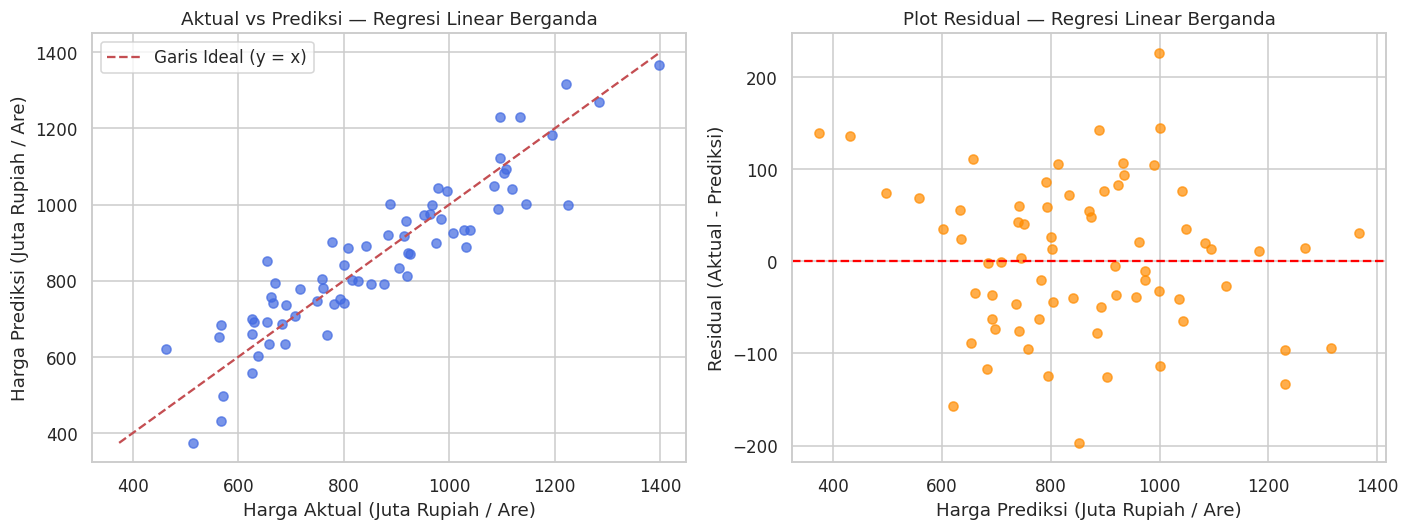

In [ ]:
# ==========================================
# 5. EVALUASI PADA DATA UJI, PERBANDINGAN TRAIN VS TEST, DAN PLOT RESIDUAL
# ==========================================
eval_rows = []
test_preds = {}

for nama, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred_train = pipe.predict(X_train)
    pred_test = pipe.predict(X_test)
    test_preds[nama] = pred_test

    eval_rows.append({
        "Model": nama,
        "Train MAE": round(mean_absolute_error(y_train, pred_train), 2),
        "Test MAE": round(mean_absolute_error(y_test, pred_test), 2),
        "Train RMSE": round(np.sqrt(mean_squared_error(y_train, pred_train)), 2),
        "Test RMSE": round(np.sqrt(mean_squared_error(y_test, pred_test)), 2),
        "Train R2": round(r2_score(y_train, pred_train), 3),
        "Test R2": round(r2_score(y_test, pred_test), 3)
    })

eval_df = pd.DataFrame(eval_rows)
display(eval_df)

# Plot Aktual vs Prediksi dan Plot Residual untuk Regresi Linear Berganda
best_model_name = "Regresi Linear Berganda (5 Fitur)"
y_pred_best = test_preds[best_model_name]
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred_best, alpha=0.7, color="royalblue")
batas = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
axes[0].plot(batas, batas, "r--", label="Garis Ideal (y = x)")
axes[0].set_xlabel("Harga Aktual (Juta Rupiah / Are)")
axes[0].set_ylabel("Harga Prediksi (Juta Rupiah / Are)")
axes[0].set_title("Aktual vs Prediksi — Regresi Linear Berganda")
axes[0].legend()

axes[1].scatter(y_pred_best, residuals, alpha=0.7, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Harga Prediksi (Juta Rupiah / Are)")
axes[1].set_ylabel("Residual (Aktual - Prediksi)")
axes[1].set_title("Plot Residual — Regresi Linear Berganda")

plt.tight_layout()
plt.show()

# Koefisien Regresi Linear Berganda
lr_best = models[best_model_name].named_steps["model"]
coef_df = pd.DataFrame({
    "Fitur": fitur_terpilih,
    "Koefisien (per 1 Standar Deviasi Fitur)": np.round(lr_best.coef_, 3)
}).sort_values(by="Koefisien (per 1 Standar Deviasi Fitur)", key=abs, ascending=False)

print(f"Intercept model berganda (pada rata-rata seluruh fitur): {lr_best.intercept_:.2f} juta/are")
display(coef_df)

### Interpretasi Metrik dan Koefisien
- **Makna MAE dalam Satuan Target:** Pada data uji, **Regresi Linear Berganda** menghasilkan **Test MAE sebesar 67.14**, artinya rata-rata selisih absolut antara harga prediksi model dan harga aktual adalah sekitar **67,14 juta rupiah per are** (jauh lebih akurat dibandingkan `DummyRegressor` dengan Test MAE 173,97 juta rupiah per are).
- **Pengecekan Overfitting:** Nilai **Train $R^2$ (0.865)** dan **Test $R^2$ (0.840)** sangat berdekatan (selisih hanya 0,025), menandakan model tidak mengalami *overfitting* dan mampu melakukan generalisasi dengan baik pada data baru.
- **Arti Koefisien Model Berganda (pada skala `StandardScaler`):** Setiap kenaikan 1 standar deviasi pada `umur_rumah_tahun` menurunkan harga rata-rata sekitar **110,33 juta/are** dan `jarak_pantai_meter` menurunkan sekitar **93,37 juta/are** (ceteris paribus), sedangkan kenaikan 1 standar deviasi `lebar_jalan_akses_meter` menaikkan harga sekitar **94,58 juta/are** dan `jumlah_minimarket_sekitar` menaikkan sekitar **54,86 juta/are**.

### Keputusan saya
Saya menguji ketiga model satu kali pada data uji yang belum pernah disentuh saat pelatihan, memvisualisasikan plot aktual vs prediksi beserta plot residual yang menyebar acak di sekitar garis nol, serta menafsirkan MAE dan bobot koefisien. Hasil ini membuktikan bahwa kombinasi kelima fitur mampu menjelaskan 84% variasi harga pada data uji tanpa gejala *overfitting*.

## 6. Kesimpulan

### Kelayakan Model dan Model Terpilih
**Regresi Linear Berganda (5 Fitur)** dinyatakan **layak dipakai** dan dipilih sebagai model utama karena dua alasan kuantitatif utama:
1. **Keunggulan Jauh di Atas Baseline:** Pada data uji, Regresi Linear Berganda menurunkan kesalahan prediksi (**Test MAE = 67,14 juta/are** dan **Test RMSE = 82,20 juta/are**) hingga lebih dari separuh dibandingkan `DummyRegressor` (**Test MAE = 173,97 juta/are** dan **Test RMSE = 206,74 juta/are**), serta meningkatkan koefisien determinasi dari **Test $R^2 = -0.012$** menjadi **Test $R^2 = 0.840$**.
2. **Lebih Unggul dari Regresi Sederhana & Stabil:** Dibandingkan regresi linear sederhana yang hanya memakai `umur_rumah_tahun` (**Test $R^2 = 0.333$**, **Test MAE = 139,30 juta/are**), penambahan 4 fitur lokasi dan akses menaikkan akurasi penjelasan varians sebesar +50,7 poin persentase dengan selisih Train–Test $R^2$ yang kecil (**0.865 vs 0.840**).

### Rekomendasi Tindakan bagi Pengguna
- **Bagi Pembeli / Investor:** Gunakan estimasi model sebagai acuan harga wajar awal; properti dengan akses jalan lebar dan jarak dekat ke pantai memiliki premi harga tertinggi sehingga layak diprioritaskan untuk nilai investasi jangka panjang.
- **Bagi Pemilik / Pengembang Properti:** Pertimbangkan perbaikan akses jalan lingkungan dan kelengkapan fasilitas komersial sekitar karena keduanya memberikan kontribusi positif signifikan terhadap harga jual per are.

### Keterbatasan dan Saran Perbaikan
- **Keterbatasan:** Model belum mencakup variabel kondisi fisik interior bangunan, status sertifikat lahan (SHM/HGB), serta kelengkapan fasilitas wisata sekitar sehingga masih menyisakan galat rata-rata ~67 juta/are.
- **Saran Perbaikan:** Tambahkan fitur kualitas bangunan dan zonasi tata ruang, serta uji model regresi terregularisasi (*Ridge/Lasso*) atau berbasis pohon (*Random Forest Regressor*) untuk menangkap potensi hubungan non-linear.

### Keputusan saya
Saya menetapkan **Regresi Linear Berganda** sebagai model akhir proyek ini berdasarkan keunggulan skor MAE, RMSE, dan $R^2$ dibanding baseline maupun regresi sederhana, serta merumuskan rekomendasi praktis dan langkah pengembangan lanjutan bagi pengguna.